In [15]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import RegularPolygon
from matplotlib.collections import PatchCollection
import stim

import os 

while 'honeycomb.py' not in os.listdir():
    os.chdir("..")

from honeycomb import CSSHoneycomb
from operations import Detector

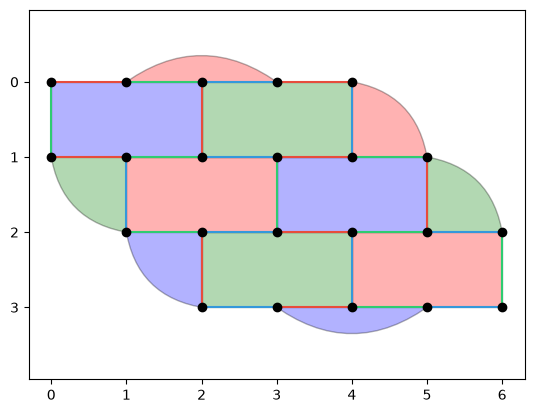

In [16]:
s = CSSHoneycomb()
s.plot_surface(show=False)
plt.savefig("testing/output/small_example.png")
plt.show()

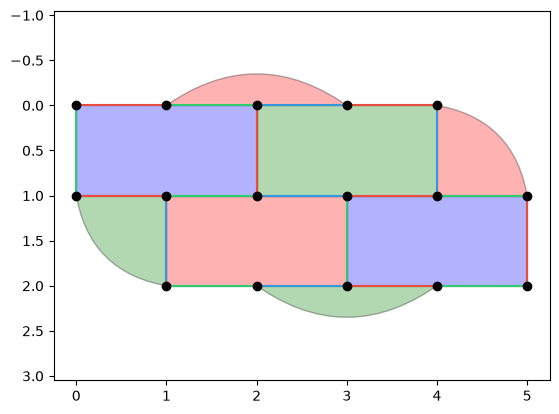

In [25]:
# TODO do we use letters or words?
COLOUR_MAP = {
    'r' : 'red',
    'g' : 'green',
    'b' : 'blue'
}

def measurement_cycle(honey: CSSHoneycomb, cycle=["rZ", "gX", "bZ", "rX", "gZ", "bX"]):
    """
    measure our stabilizers
    """

    string = ""
    for m in cycle:
        
        if m == "gZ":
            print("" ,end="")
        
        colour = COLOUR_MAP[m[0]]
        flavour = m[1]

        string += f"#{colour}{flavour}\n"
        string += honey.get_measurement(colour, flavour) + "\n"
        string += honey.tick()
        
        # detectors = honey.get_detectors()
        # string += honey.write_detectors(detectors, honey.clock)
        
        # print(detectors)
    
    return string

s = CSSHoneycomb(ncols=5, nrows=3)
s.plot_surface()
string = s.initialise_circuit()
string += s.prepare_qubits()
string += measurement_cycle(s, cycle=["rX", "gZ", "bX", 'rZ', "gX", "bZ"])

In [26]:
print(string)

# data qubits
QUBIT_COORDS(0,0) 0
QUBIT_COORDS(1,0) 1
QUBIT_COORDS(2,0) 2
QUBIT_COORDS(3,0) 3
QUBIT_COORDS(4,0) 4
QUBIT_COORDS(0,1) 5
QUBIT_COORDS(1,1) 6
QUBIT_COORDS(2,1) 7
QUBIT_COORDS(3,1) 8
QUBIT_COORDS(4,1) 9
QUBIT_COORDS(5,1) 10
QUBIT_COORDS(1,2) 11
QUBIT_COORDS(2,2) 12
QUBIT_COORDS(3,2) 13
QUBIT_COORDS(4,2) 14
QUBIT_COORDS(5,2) 15
# ancilla qubits
QUBIT_COORDS(0.0,0.5) 16
QUBIT_COORDS(0.5,0.0) 17
QUBIT_COORDS(1.5,0.0) 18
QUBIT_COORDS(2.0,0.5) 19
QUBIT_COORDS(2.5,0.0) 20
QUBIT_COORDS(3.5,0.0) 21
QUBIT_COORDS(4.0,0.5) 22
QUBIT_COORDS(0.5,1.0) 23
QUBIT_COORDS(1.0,1.5) 24
QUBIT_COORDS(1.5,1.0) 25
QUBIT_COORDS(2.5,1.0) 26
QUBIT_COORDS(3.0,1.5) 27
QUBIT_COORDS(3.5,1.0) 28
QUBIT_COORDS(4.5,1.0) 29
QUBIT_COORDS(5.0,1.5) 30
QUBIT_COORDS(1.5,2.0) 31
QUBIT_COORDS(2.5,2.0) 32
QUBIT_COORDS(3.5,2.0) 33
QUBIT_COORDS(4.5,2.0) 34
# initialise qubits in |0>
R 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 #redX
# prepare ancillas in X basis
R 17 19 21 23 28 30 33 
TICK
H 17 19 21 23 28 30 33 
TICK
# fold 

In [27]:
c = stim.Circuit(string)

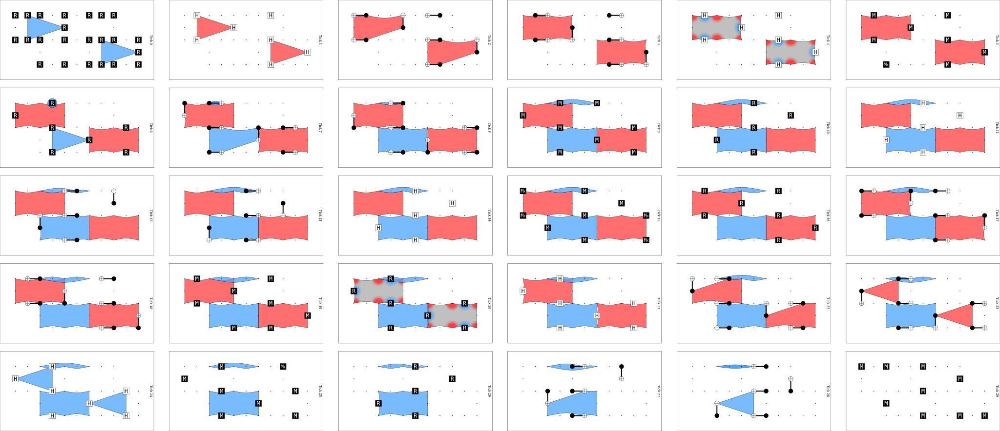

In [28]:
c.diagram("detslice-with-ops-svg")

In [21]:
# looks like we are missing Z boundary stabilizer

In [22]:
# len(c.shortest_graphlike_error()) # TODO

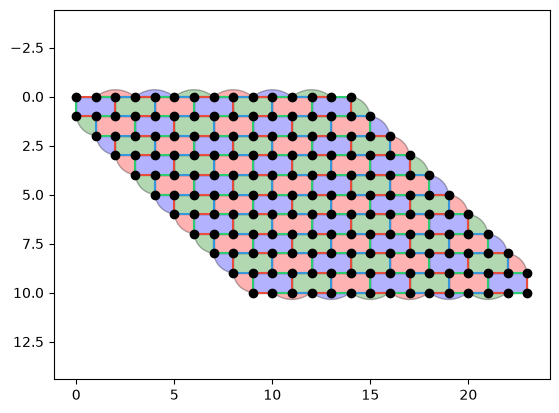

In [23]:
# TODO do we use letters or words?
cycle = ["rZ", "gX", "bZ", "rX", "gZ", "bX", "rZ", "gX", "bZ", "rX", "gZ", "bX"]

s = CSSHoneycomb(ncols=15, nrows=11)
s.plot_surface()
string = s.initialise_circuit()
string += measurement_cycle(s, cycle)

In [24]:
c = stim.Circuit(string)
c.diagram("detslice-with-ops-svg")